# 04 — Avaliação do RAG Jurídico e Validações da Camada de IA

Este notebook avalia a camada de recuperação jurídica e validação do **FraudRadar PLD** sem
chamar a API do Gemini e sem depender do PostgreSQL:
1. **Snapshots versionados (`rag/snapshots/`):** validação de integridade (`prepare_legal_snapshot`)
   da **Lei nº 9.613/1998** (`reviewed`, ativa no chat) e da **Circular BCB nº 3.978/2020**
   (`pending_review`, aguardando revisão humana);
2. **Avaliação de recuperação híbrida (semântica + léxica):** taxa de acerto (Hit@3 e Hit@5) para um
   conjunto de perguntas jurídicas típicas de PLD, comparando busca puramente vetorial
   (`intfloat/multilingual-e5-small`) contra a pontuação híbrida de `fraudradar.ai.legal_hybrid`;
3. **Contrato de apresentação e pseudonimização:** validação determinística de citações
   (`present_legal_rag`) e garantia de que o LLM nunca recebe números reais de conta.


In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraudradar.ai.chunking import split_document
from fraudradar.ai.documents import RetrievedDocument
from fraudradar.ai.embeddings import EmbeddingService
from fraudradar.ai.legal_hybrid import _concepts, _explicit_article
from fraudradar.ai.legal_ingestion import prepare_legal_snapshot
from fraudradar.ai.legal_presentation import present_legal_rag
from fraudradar.ai.legal_resilience import LegalRagResult
from fraudradar.config import ROOT_DIR

plt.rcParams["figure.dpi"] = 110
SNAPSHOTS_DIR = ROOT_DIR / "rag" / "snapshots"

## 1. Integridade e chunking dos snapshots normativos (`prepare_legal_snapshot`)

Verificamos todos os snapshots em `rag/snapshots/` com o mesmo validador usado por
`python -m worker rag-load`.


In [2]:
rows = []
snapshots = {}
for path in sorted(SNAPSHOTS_DIR.glob("*.json")):
    snap = json.loads(path.read_text(encoding="utf-8-sig"))
    prepared = prepare_legal_snapshot(snap)
    snapshots[snap["source_id"]] = (snap, prepared)
    rows.append(
        {
            "arquivo": path.name,
            "source_id": snap["source_id"],
            "review_status": snap["review_status"],
            "artigos": len(prepared),
            "chunks": sum(p.expected_chunks for p in prepared),
        }
    )

display(pd.DataFrame(rows))

,arquivo,source_id,review_status,artigos,chunks
0,circular-bcb-3978-2020-ad03384f41bc1a00.json,circular-bcb-3978-2020,pending_review,70,94
1,lei-9613-1998-4903b5e6bb866411.json,lei-9613-1998,reviewed,28,58


## 2. Avaliação da recuperação híbrida na Lei nº 9.613/1998 (`reviewed`)

Geramos os embeddings locais com `EmbeddingService` (`intfloat/multilingual-e5-small`, 384
dimensões) para todos os trechos da Lei 9.613/1998 e comparamos, sobre 8 perguntas de PLD, a
recuperação apenas semântica vs. a pontuação híbrida usada pelo sistema (`0.65 * cobertura_conceitos
+ 0.35 * similaridade + 2.0 * artigo_explicito`).


In [3]:
lei_snap, lei_articles = snapshots["lei-9613-1998"]
chunks = []
for art in lei_articles:
    parts = split_document(
        art.content,
        max_chars=art.metadata["chunking_max_chars"],
        overlap_chars=art.metadata["chunking_overlap_chars"],
    )
    for part in parts:
        chunks.append(
            {
                "id": len(chunks) + 1,
                "source": art.source,
                "chunk_index": part.index,
                "article": art.reference,
                "content": part.content,
                "metadata": art.metadata,
            }
        )

embedder = EmbeddingService()
doc_vectors = embedder.embed_documents([c["content"] for c in chunks])
print(
    f"Base indexada em memória: {len(chunks)} trechos da Lei 9.613/1998 "
    f"(dim={doc_vectors.shape[1]})"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Base indexada em memória: 58 trechos da Lei 9.613/1998 (dim=384)


,pergunta,esperado,top3_hibrido,hit3_sem,hit3_hyb,hit5_hyb
0,Qual a pena para o crime de lavagem de dinheiro?,Art. 1,"Art. 1, Art. 7",True,True,True
1,Quando a pena de lavagem pode ser aumentada po...,Art. 1,"Art. 1, Art. 12",True,True,True
2,Quais sao os deveres de identificacao de clien...,Art. 10,"Art. 10, Art. 10-A",True,True,True
3,Por quanto tempo os registros das operacoes fi...,Art. 10,"Art. 10, Art. 17-E",True,True,True
4,Qual o prazo e a obrigacao de comunicacao de o...,Art. 11,"Art. 11, Art. 14, Art. 15",True,True,True
5,A comunicacao de boa-fe ao COAF gera responsab...,Art. 11,"Art. 11, Art. 15",True,True,True
6,Quais sao as penalidades administrativas e mul...,Art. 12,Art. 12,True,True,True
7,O que diz o art. 17-B sobre acesso a dados cad...,Art. 17-B,"Art. 17-B, Art. 10, Art. 10-A",True,True,True


,Metrica,Taxa (%)
0,Hit@3 Semântico,100.0
1,Hit@3 Híbrido,100.0
2,Hit@5 Semântico,100.0
3,Hit@5 Híbrido,100.0


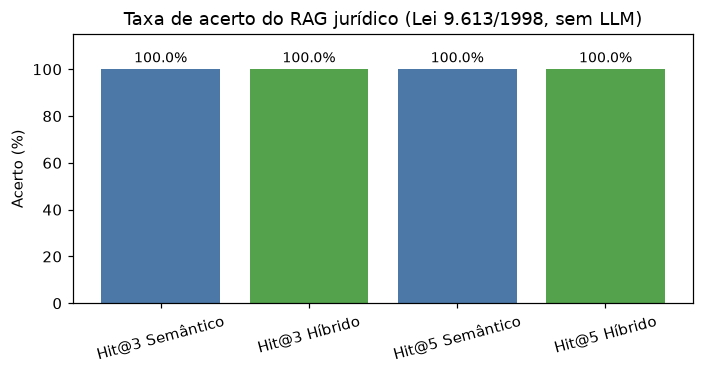

In [4]:
EVAL_SET = [
    ("Qual a pena para o crime de lavagem de dinheiro?", {"Art. 1"}),
    (
        "Quando a pena de lavagem pode ser aumentada por organizacao criminosa ou ativo virtual?",
        {"Art. 1"},
    ),
    ("Quais sao os deveres de identificacao de clientes e manutencao de cadastros?", {"Art. 10"}),
    ("Por quanto tempo os registros das operacoes financeiras devem ser conservados?", {"Art. 10"}),
    ("Qual o prazo e a obrigacao de comunicacao de operacoes suspeitas ao COAF?", {"Art. 11"}),
    ("A comunicacao de boa-fe ao COAF gera responsabilidade civil ou administrativa?", {"Art. 11"}),
    (
        "Quais sao as penalidades administrativas e multas aplicaveis pelo descumprimento?",
        {"Art. 12"},
    ),
    (
        "O que diz o art. 17-B sobre acesso a dados cadastrais sem autorizacao judicial?",
        {"Art. 17-B"},
    ),
]

records = []
for question, expected_articles in EVAL_SET:
    q_vec = embedder.embed_query(question)
    sims = doc_vectors @ q_vec
    q_concepts = _concepts(question)
    req_art = _explicit_article(question)

    sem_order = np.argsort(-sims)
    hyb_scores = []
    for idx, c in enumerate(chunks):
        c_concepts = _concepts(c["content"])
        cov = len(q_concepts & c_concepts) / len(q_concepts) if q_concepts else 0.0
        exact = req_art is not None and req_art == c["article"]
        hyb_scores.append(0.65 * cov + 0.35 * float(sims[idx]) + (2.0 if exact else 0.0))
    hyb_order = np.argsort(-np.array(hyb_scores))

    sem_top3 = [chunks[i]["article"] for i in sem_order[:3]]
    hyb_top3 = [chunks[i]["article"] for i in hyb_order[:3]]
    sem_top5 = [chunks[i]["article"] for i in sem_order[:5]]
    hyb_top5 = [chunks[i]["article"] for i in hyb_order[:5]]

    records.append(
        {
            "pergunta": question[:52] + ("..." if len(question) > 52 else ""),
            "esperado": ", ".join(sorted(expected_articles)),
            "top3_semantico": ", ".join(dict.fromkeys(sem_top3)),
            "top3_hibrido": ", ".join(dict.fromkeys(hyb_top3)),
            "hit3_sem": bool(expected_articles & set(sem_top3)),
            "hit3_hyb": bool(expected_articles & set(hyb_top3)),
            "hit5_sem": bool(expected_articles & set(sem_top5)),
            "hit5_hyb": bool(expected_articles & set(hyb_top5)),
        }
    )

eval_df = pd.DataFrame(records)
display(eval_df[["pergunta", "esperado", "top3_hibrido", "hit3_sem", "hit3_hyb", "hit5_hyb"]])

summary = pd.DataFrame(
    {
        "Metrica": ["Hit@3 Semântico", "Hit@3 Híbrido", "Hit@5 Semântico", "Hit@5 Híbrido"],
        "Taxa (%)": [
            eval_df["hit3_sem"].mean() * 100,
            eval_df["hit3_hyb"].mean() * 100,
            eval_df["hit5_sem"].mean() * 100,
            eval_df["hit5_hyb"].mean() * 100,
        ],
    }
)
display(summary.round(1))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(summary["Metrica"], summary["Taxa (%)"], color=["#4C78A8", "#54A24B", "#4C78A8", "#54A24B"])
ax.set_ylim(0, 115)
ax.set_ylabel("Acerto (%)")
ax.set_title("Taxa de acerto do RAG jurídico (Lei 9.613/1998, sem LLM)")
for i, v in enumerate(summary["Taxa (%)"]):
    ax.text(i, v + 3, f"{v:.1f}%", ha="center", fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 3. Validação determinística do contrato de evidências (`present_legal_rag`)

Demonstramos o mecanismo de resiliência quando o LLM não é chamado (`status="llm_unavailable"`):
os trechos recuperados são devolvidos com metadados auditáveis e sinalização explícita caso
algum trecho ainda esteja em `pending_review`.


In [5]:
top_chunk = chunks[0]
doc = RetrievedDocument(
    id=top_chunk["id"],
    source=top_chunk["source"],
    chunk_index=top_chunk["chunk_index"],
    content=top_chunk["content"],
    metadata=top_chunk["metadata"],
    similarity=0.82,
)
fallback_payload = present_legal_rag(
    LegalRagResult(status="llm_unavailable", answer=None, documents=(doc,), citation_ids=("F1",))
)
print("Status fallback:", fallback_payload["status"])
print("Requer revisão jurídica:", fallback_payload["requires_legal_review"])
print("Artigo citado:", fallback_payload["evidences"][0]["article"])

Status fallback: llm_unavailable
Requer revisão jurídica: False
Artigo citado: Art. 1
